# Fitting a model to features

The features can be differentiated, so a model can be fitted to them by gradient
descent. This example fits the sodium and potassium conductances of a
Hodgkin-Huxley model to the features of three current steps that were simulated
with known conductances. The fit starts from a model that is silent at the weakest
step.

In [1]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

jax.config.update("jax_enable_x64", True)

from jaxley_ephys import detect_spikes, spike_features, sweep_features  # noqa: E402

## A Hodgkin-Huxley model

The classic squid-axon model, integrated with forward Euler steps of 25 µs: 100 ms
with a current step from 10 to 90 ms. The conductances are passed as logarithms,
which keeps them positive during the fit. Any differentiable simulator works the
same way, e.g. [Jaxley](https://github.com/jaxleyverse/jaxley).

In [2]:
DT = 0.025  # ms
START, END = 10.0, 90.0  # ms, current step


def gates(v):
    """Opening and closing rates (1/ms) of the m, h and n gates at v (mV)."""
    return (
        0.1 * (v + 40) / (1 - jnp.exp(-(v + 40) / 10)),
        4 * jnp.exp(-(v + 65) / 18),
        0.07 * jnp.exp(-(v + 65) / 20),
        1 / (1 + jnp.exp(-(v + 35) / 10)),
        0.01 * (v + 55) / (1 - jnp.exp(-(v + 55) / 10)),
        0.125 * jnp.exp(-(v + 65) / 80),
    )


def simulate(log_g, amp):
    """t (s), v (mV) and i (uA/cm2) for a current step of amplitude amp."""
    g_na, g_k = jnp.exp(log_g)
    t = jnp.arange(0.0, 100.0, DT)
    i = jnp.where((t >= START) & (t < END), amp, 0.0)

    def step(state, i_n):
        v, m, h, n = state
        am, bm, ah, bh, an, bn = gates(v)
        i_ion = g_na * m**3 * h * (v - 50) + g_k * n**4 * (v + 77) + 0.3 * (v + 54.4)
        m = m + DT * (am * (1 - m) - bm * m)
        h = h + DT * (ah * (1 - h) - bh * h)
        n = n + DT * (an * (1 - n) - bn * n)
        return (v + DT * (i_n - i_ion), m, h, n), v

    am, bm, ah, bh, an, bn = gates(-65.0)
    rest = (-65.0, am / (am + bm), ah / (ah + bh), an / (an + bn))
    return 1e-3 * t, jax.lax.scan(step, rest, i)[1], i

## Features

The fit compares four features per step: the firing rate, the mean interspike
interval, and the peak and fast-trough voltage of the first spike. Two options of
`jaxley_ephys` make them suitable for gradient descent:

- `interpolate=True` places spike events between samples, so that their times,
  and with them the interspike intervals, change smoothly with the conductances;
- `nan_to=0.0` replaces undefined features (e.g. the interval with fewer than two
  spikes) by 0: a NaN in the loss would make all gradients NaN.

Spike counts change in steps. The firing rate has the gradient of a soft count of
the voltage's upward crossings of -30 mV instead, which also pushes a silent model
towards spiking; `count_width` (mV) sets how far it reaches.

In [3]:
AMPS = jnp.array([6.0, 10.0, 14.0])  # uA/cm2
NAMES = ["avg_rate", "mean_isi", "peak_v", "fast_trough_v"]


def features(log_g, amp):
    t, v, i = simulate(log_g, amp)
    sp = detect_spikes(
        t,
        v,
        i,
        START / 1e3,
        END / 1e3,
        max_spikes=32,
        interpolate=True,
        count_width=10.0,
    )
    sweep, spike = sweep_features(sp, nan_to=0.0), spike_features(sp, nan_to=0.0)
    return jnp.stack(
        [
            sweep["avg_rate"],
            sweep["mean_isi"],
            spike["peak_v"][0],
            spike["fast_trough_v"][0],
        ]
    )


all_features = jax.vmap(features, in_axes=(None, 0))  # the three steps at once
true_log_g = jnp.log(jnp.array([120.0, 36.0]))  # g_Na, g_K (mS/cm2)
start_log_g = jnp.log(jnp.array([60.0, 50.0]))
target = all_features(true_log_g, AMPS)


def table(log_g):
    return pd.DataFrame(
        np.asarray(all_features(log_g, AMPS)), index=AMPS, columns=NAMES
    )


table(start_log_g).join(table(true_log_g), rsuffix=" (target)")

,avg_rate,mean_isi,peak_v,fast_trough_v,avg_rate (target),mean_isi (target),peak_v (target),fast_trough_v (target)
6.0,0.0,0.0,0.000000,0.000000,25.0,19.689540,40.113238,-75.542059
10.0,12.5,0.0,22.326360,-74.933590,75.0,14.704928,40.932364,-75.127647
14.0,0.0,0.0,26.125105,-74.539765,87.5,13.198971,41.448494,-74.725825


## Gradient descent

The loss is the mean squared relative error of the features. It changes smoothly
between changes of the spike counts and jumps at them, so the fit uses Adam with a
decaying step size and keeps the best parameters seen.

In [4]:
scale = jnp.maximum(jnp.abs(target), 1.0)


@jax.jit
@jax.value_and_grad
def loss(log_g):
    return jnp.mean(((all_features(log_g, AMPS) - target) / scale) ** 2)


log_g, m, s = start_log_g, 0.0, 0.0
history, best = [], (np.inf, start_log_g)
started = time.perf_counter()
for k in range(1, 201):
    value, grad = loss(log_g)
    history.append([float(value), *np.exp(np.asarray(log_g))])
    if value < best[0]:
        best = (float(value), log_g)
    m, s = 0.9 * m + 0.1 * grad, 0.999 * s + 0.001 * grad**2  # Adam
    log_g = log_g - 0.05 * 0.985**k * (m / (1 - 0.9**k)) / (
        jnp.sqrt(s / (1 - 0.999**k)) + 1e-8
    )
fitted = np.exp(np.asarray(best[1]))
print(
    f"{time.perf_counter() - started:.0f} s; best loss {best[0]:.1e} at g_Na, g_K = {fitted}"
)
table(best[1]).join(table(true_log_g), rsuffix=" (target)")

26 s; best loss 2.5e-04 at g_Na, g_K = [103.48633278  31.57745601]


,avg_rate,mean_isi,peak_v,fast_trough_v,avg_rate (target),mean_isi (target),peak_v (target),fast_trough_v (target)
6.0,25.0,19.687133,38.769499,-75.286763,25.0,19.689540,40.113238,-75.542059
10.0,75.0,14.521154,39.770242,-74.815237,75.0,14.704928,40.932364,-75.127647
14.0,87.5,12.989054,40.389283,-74.346236,87.5,13.198971,41.448494,-74.725825


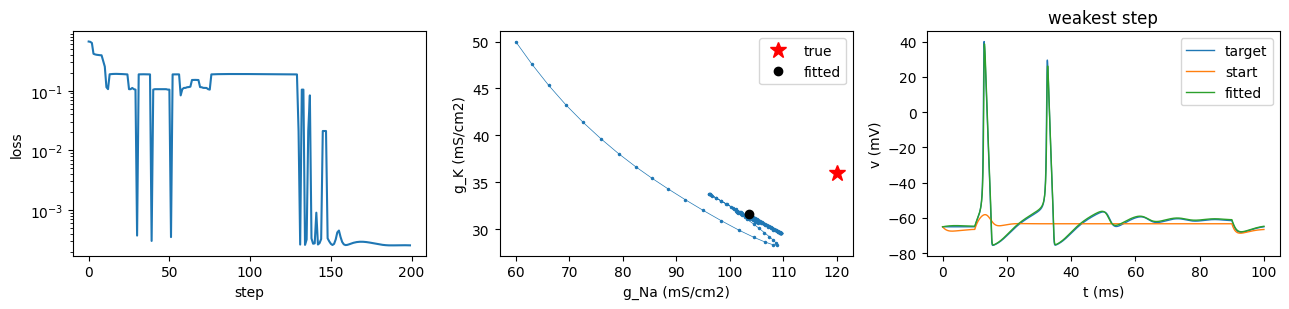

In [5]:
history = np.array(history)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].semilogy(history[:, 0])
axes[0].set(xlabel="step", ylabel="loss")
axes[1].plot(history[:, 1], history[:, 2], ".-", ms=3, lw=0.5)
axes[1].plot(120.0, 36.0, "r*", ms=12, label="true")
axes[1].plot(*fitted, "ko", label="fitted")
axes[1].set(xlabel="g_Na (mS/cm2)", ylabel="g_K (mS/cm2)")
axes[1].legend()
for log_g, label in (
    (true_log_g, "target"),
    (start_log_g, "start"),
    (best[1], "fitted"),
):
    t, v, _ = simulate(log_g, AMPS[0])
    axes[2].plot(1e3 * t, v, lw=1, label=label)
axes[2].set(xlabel="t (ms)", ylabel="v (mV)", title="weakest step")
axes[2].legend()
plt.tight_layout()
plt.show()

The fitted model reproduces the target features. Its conductances are close to
the true ones, but not equal: these features mostly constrain the ratio of the two
conductances, and the fit ends in a valley of models with nearly the same features.
More features or steps narrow it down. Because spike counts make the loss jump,
the fit keeps the best parameters, and where it ends depends on details such as
the step size; for recorded data, a loss on the voltage trace or a fit in stages can
be more robust.